In [2]:
import h5py
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.ndimage import label
from skimage import morphology
from skimage import measure
from scipy import ndimage as ndi
from skimage.segmentation import find_boundaries
from scipy.stats import gaussian_kde
from matplotlib.patches import FancyArrowPatch
from scipy.optimize import curve_fit
from scipy.ndimage import map_coordinates
import seaborn as sns
from scipy.ndimage import maximum_filter, label
from scipy.stats import skewnorm
from scipy.stats import lognorm

# shared code and paths (see README.md and shared/)
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "shared" / "paths.py").exists())
sys.path.insert(0, str(REPO))
from shared.fields import partial_x_fft, partial_y_fft
from shared.paths import DATA_ROOT, NAS_ROOT, results_dir, cache_dir as shared_cache_dir
RESULTS = results_dir("jpar_jperp", "Jpar_CSDetectionBeta1")

In [3]:
#Defining all the required functions

#Fourier Transform Functions


#Defining constants
dx = 0.0625
dy = 0.0625

In [4]:
#Denoising the data
def gaussian_fft_filter_2d(J_squared, k0):
    """
    Apply a Gaussian low-pass filter in Fourier space to a 2D field.

    Parameters
    ----------
    J_squared : 2D numpy array
        Input real-space data
    k0 : float
        Filter width in k-space (grid units). Smaller = stronger smoothing.

    Returns
    -------
    J_filtered : 2D numpy array
        Smoothed real-space data
    """

    # FFT
    F = np.fft.fft2(J_squared)
    F_shifted = np.fft.fftshift(F)

    # k-grid
    nx, ny = J_squared.shape
    kx = np.fft.fftshift(np.fft.fftfreq(nx)) * nx
    ky = np.fft.fftshift(np.fft.fftfreq(ny)) * ny
    KX, KY = np.meshgrid(kx, ky, indexing='ij')
    K2 = KX**2 + KY**2

    # Gaussian filter in k-space
    gaussian = np.exp(-K2 / (2 * k0**2))

    # Apply filter
    F_filt = F_shifted * gaussian

    # Inverse FFT
    F_filt = np.fft.ifftshift(F_filt)
    J_filtered = np.fft.ifft2(F_filt)

    # Return real part
    return np.real(J_filtered)

In [5]:
#Lets Computer J_total

# # 1. Read the HDF5 file
File_Bx = f'{DATA_ROOT}/beta_p_1/beta_e_1/Bx_ApJ_t40.h5'  # Replace with your file path
File_By = f'{DATA_ROOT}/beta_p_1/beta_e_1/By_ApJ_t40.h5'  # Replace with your file path
File_Bz = f'{DATA_ROOT}/beta_p_1/beta_e_1/Bz_ApJ_t40.h5'  # Replace with your file path

with h5py.File(File_Bx, 'r') as fBx, h5py.File(File_By, 'r') as fBy, h5py.File(File_Bz, 'r') as fBz:
    data_Bx = fBx['DS1'][:].T
    data_By = fBy['DS1'][:].T
    data_Bz = fBz['DS1'][:].T
    data_Bx_filtered = gaussian_fft_filter_2d(data_Bx, k0=0.3 * len(data_Bx))
    data_By_filtered = gaussian_fft_filter_2d(data_By, k0=0.3 * len(data_Bx))
    data_Bz_filtered = gaussian_fft_filter_2d(data_Bz, k0=0.3 * len(data_Bx))
    data_Jx = partial_y_fft(data_Bz_filtered,dx)
    data_Jy = -partial_x_fft(data_Bz_filtered,dy)
    data_Jz = partial_x_fft(data_By_filtered,dy)-partial_y_fft(data_Bx_filtered,dx)

J_squared = data_Jx**2 + data_Jy**2 + data_Jz**2
# J_squared = gaussian_fft_filter_2d(J_squared, k0=0.2 * len(data_Bx))

Jpar_squared = ((data_Jx*data_Bx + data_Jy*data_By + data_Jz*data_Bz)**2)/(data_Bx**2 + data_By**2 + data_Bz**2)
Jperp_squared = J_squared - Jpar_squared

Jpar_squared = gaussian_fft_filter_2d(Jpar_squared, k0=0.3 * len(data_Bx))
Jperp_squared = gaussian_fft_filter_2d(Jperp_squared, k0=0.3 * len(data_Bx))

#Different Strategies for Threshold
#Strategy 1: Pick top 10% of the features
threshold = np.quantile(Jpar_squared, 0.9)

print("Threshold:", threshold)

binary_mask = np.abs(Jpar_squared) > threshold


#MORPHOLOGICAL SMOOTHING
struct = morphology.disk(5)

smoothed_mask = morphology.binary_opening(binary_mask, struct)
smoothed_mask = morphology.binary_closing(smoothed_mask, struct)
smoothed_mask = smoothed_mask.astype(int)

#Remove small areas
min_area = 300 # choose based on eye balling
cleaned_mask = morphology.remove_small_objects(smoothed_mask.astype(bool), min_size=min_area).astype(int)

Threshold: 0.026438491647504118


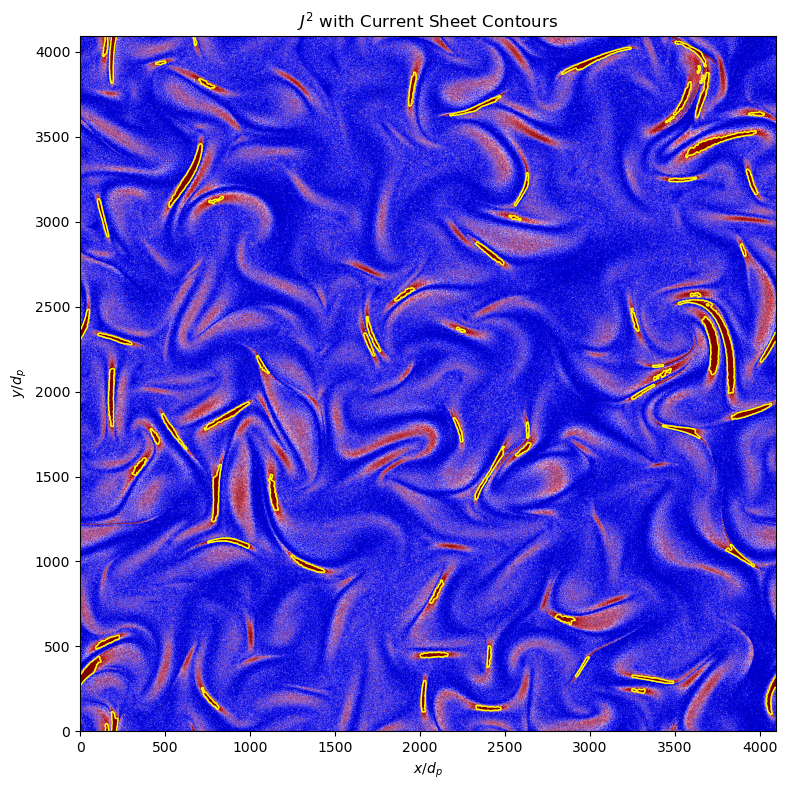

In [6]:
#Plot current sheets over the base J_squared field

plt.figure(figsize=(10, 8))

# Base field
plt.imshow(Jpar_squared.T, cmap='seismic', origin='lower', vmax=0.05)

# Add current-sheet boundaries
plt.contour(cleaned_mask.T, levels=[0.5], colors='yellow', linewidths=1)

plt.title(r'$J^{2}$ with Current Sheet Contours')
plt.xlabel(r'$x/d_p$')
plt.ylabel(r'$y/d_p$')
plt.tight_layout()
plt.savefig(RESULTS / "Jpar_with_CS_contours_beta1.png", dpi=300)
plt.show()

In [7]:
#FIND MAXIMUM IN EACH CONNECTED REGION

labeled_mask, num_features = label(cleaned_mask)
print("Regions found:", num_features)

max_coords = []
max_values = []

for i in range(1, num_features + 1):
    region_mask = (labeled_mask == i)
    region_vals = Jpar_squared[region_mask]

    if region_vals.size == 0:
        continue

    # Extreme value (max magnitude)
    max_pos = np.argmax(np.abs(region_vals))
    extreme_value = region_vals[max_pos]
    max_values.append(extreme_value)

    # Convert index → coordinates
    xs, ys = np.where(region_mask)
    max_coords.append((xs[max_pos], ys[max_pos]))

Regions found: 72


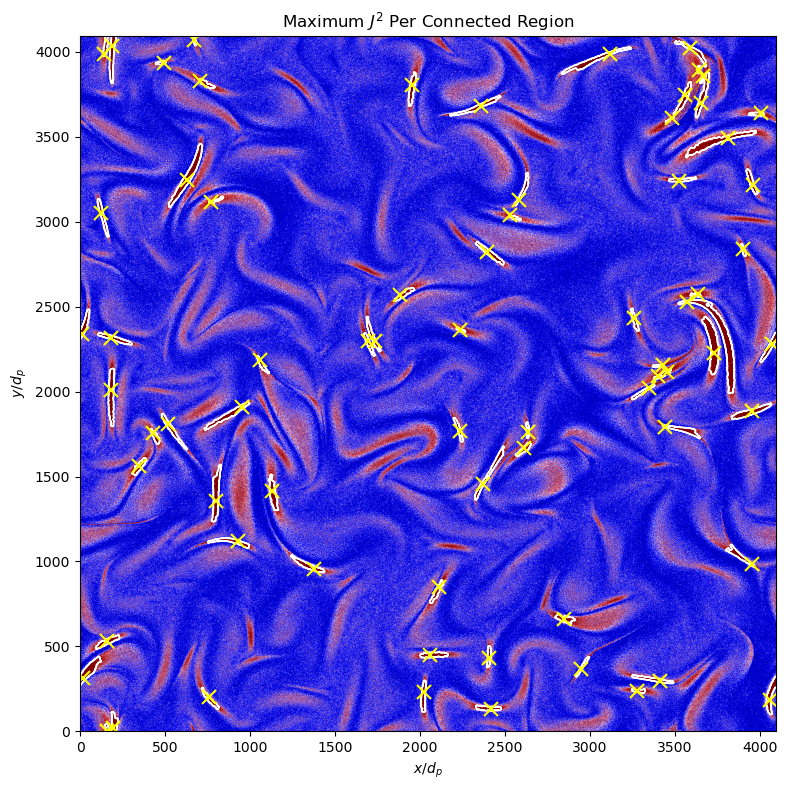

In [8]:
# PLOT ORIGINAL FIELD + MASK + MAXIMUM POINTS

plt.figure(figsize=(10, 8))

# --- Base field ---
plt.imshow(Jpar_squared.T, cmap='seismic', origin='lower', vmax=0.05)

# --- Boundaries of CSs---
boundaries = find_boundaries(labeled_mask)
plt.contour(boundaries.T, levels=[0.5], colors='white', linewidths=1)

# --- Overlay maxima as yellow crosses ---
for x, y in max_coords:
    plt.plot(x, y, marker='x', markersize=10, markeredgewidth=1.5, color='yellow')

plt.title(r'Maximum $J^{2}$ Per Connected Region')
plt.xlabel(r'$x/d_p$')
plt.ylabel(r'$y/d_p$')

plt.tight_layout()
plt.savefig(RESULTS / "Jpar_maxima_overlay_beta1.png", dpi=300)
plt.show()

In [9]:
# Method 1 for Thickness Computation: Using the internal function for diameter of largest inscribed circle

#1. Labelling each connected region

labeled_mask = measure.label(cleaned_mask, connectivity=2)
num_regions = labeled_mask.max()
print("Number of connected regions:", num_regions)

#2. Compute thicknesses

thicknesses_m1 = []

for label_id in range(1, num_regions + 1):

    region = (labeled_mask == label_id)

    # Euclidean distance transform INSIDE the region
    dist = ndi.distance_transform_edt(region)

    # Full sheet thickness = diameter of largest inscribed circle
    thickness = 2 * dist.max()

    thicknesses_m1.append(thickness)

# 3. Some Central Measures of the statistics

print(f"Found {len(thicknesses_m1)} sheets")
print(f"Mean thickness = {np.mean(thicknesses_m1):.3f} pixels")
print(f"Median thickness = {np.median(thicknesses_m1):.3f} pixels")
print(f"Min thickness = {np.min(thicknesses_m1):.3f} px, Max = {np.max(thicknesses_m1):.3f} px")

Number of connected regions: 72
Found 72 sheets
Mean thickness = 25.830 pixels
Median thickness = 24.125 pixels
Min thickness = 12.166 px, Max = 52.000 px


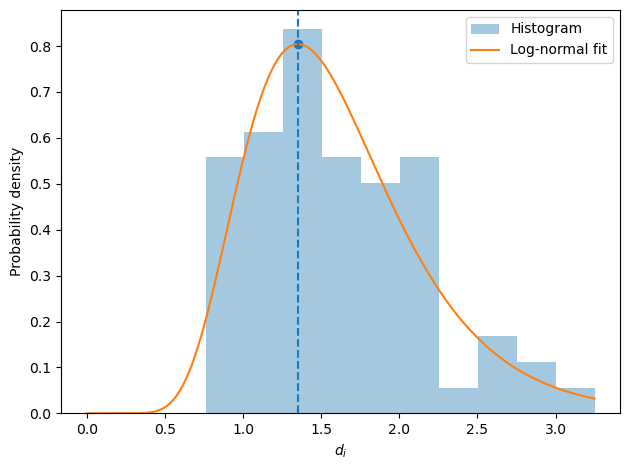

In [10]:
x = np.array(thicknesses_m1)   # in pixels
x = x[x > 0]

# Convert pixels -> d_i
x_di = x / 16.0

# Fit log-normal in d_i units
# shape, loc, scale = lognorm.fit(x_di, floc=0)
shape, loc, scale = lognorm.fit(x_di)

xs = np.linspace(0, x_di.max(), 300)

# Compute mode (peak of the PDF)
x_mode = loc + scale * np.exp(-shape**2)
y_mode = lognorm.pdf(x_mode, shape, loc, scale)

plt.hist(x_di, bins=10, density=True, alpha=0.4, label="Histogram")
plt.plot(xs, lognorm.pdf(xs, shape, loc, scale), label="Log-normal fit")

# Mark the peak
plt.axvline(x_mode, linestyle="--")
plt.scatter([x_mode], [y_mode])

plt.xlabel(r"$d_i$")
plt.ylabel("Probability density")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / "Jpar_PDF_beta1.png", dpi=300)
plt.show()

In [11]:
#Different Strategies for Threshold
#Strategy 1: Pick top 10% of the features
threshold = np.quantile(Jperp_squared, 0.8)

print("Threshold:", threshold)

binary_mask = np.abs(Jperp_squared) > threshold


#MORPHOLOGICAL SMOOTHING
struct = morphology.disk(5)

smoothed_mask = morphology.binary_opening(binary_mask, struct)
smoothed_mask = morphology.binary_closing(smoothed_mask, struct)
smoothed_mask = smoothed_mask.astype(int)

#Remove small areas
min_area = 300 # choose based on eye balling
cleaned_mask = morphology.remove_small_objects(smoothed_mask.astype(bool), min_size=min_area).astype(int)

Threshold: 0.009335267631438634


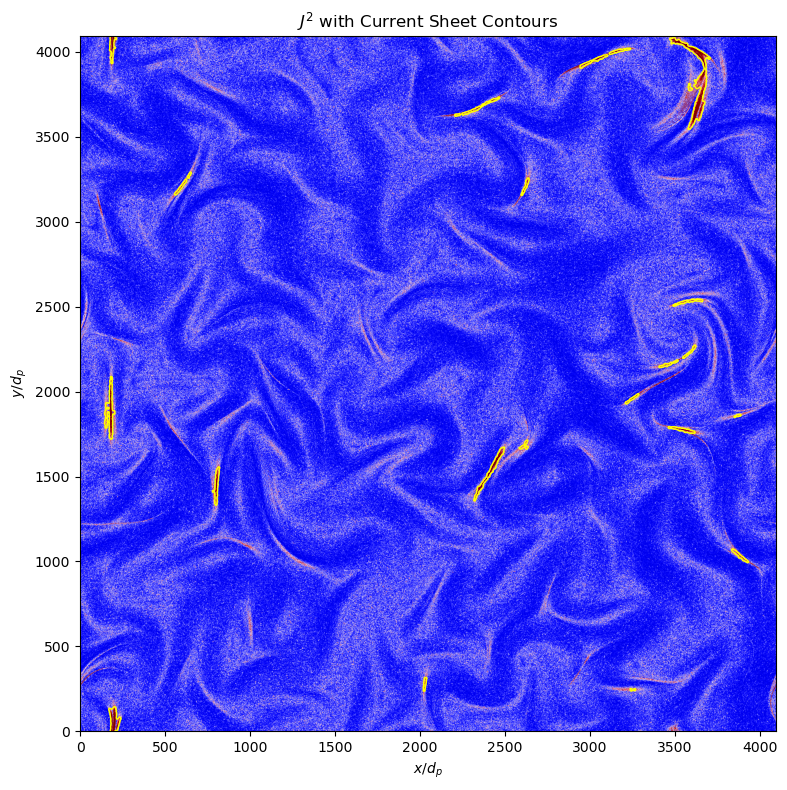

In [12]:
#Plot current sheets over the base J_squared field

plt.figure(figsize=(10, 8))

# Base field
plt.imshow(Jperp_squared.T, cmap='seismic', origin='lower', vmax=0.05)

# Add current-sheet boundaries
plt.contour(cleaned_mask.T, levels=[0.5], colors='yellow', linewidths=1)

plt.title(r'$J^{2}$ with Current Sheet Contours')
plt.xlabel(r'$x/d_p$')
plt.ylabel(r'$y/d_p$')
plt.tight_layout()
plt.savefig(RESULTS / "Jperp_with_CS_contours_beta1.png", dpi=300)
plt.show()

In [13]:
#FIND MAXIMUM IN EACH CONNECTED REGION

labeled_mask, num_features = label(cleaned_mask)
print("Regions found:", num_features)

max_coords = []
max_values = []

for i in range(1, num_features + 1):
    region_mask = (labeled_mask == i)
    region_vals = Jperp_squared[region_mask]

    if region_vals.size == 0:
        continue

    # Extreme value (max magnitude)
    max_pos = np.argmax(np.abs(region_vals))
    extreme_value = region_vals[max_pos]
    max_values.append(extreme_value)

    # Convert index → coordinates
    xs, ys = np.where(region_mask)
    max_coords.append((xs[max_pos], ys[max_pos]))

Regions found: 26


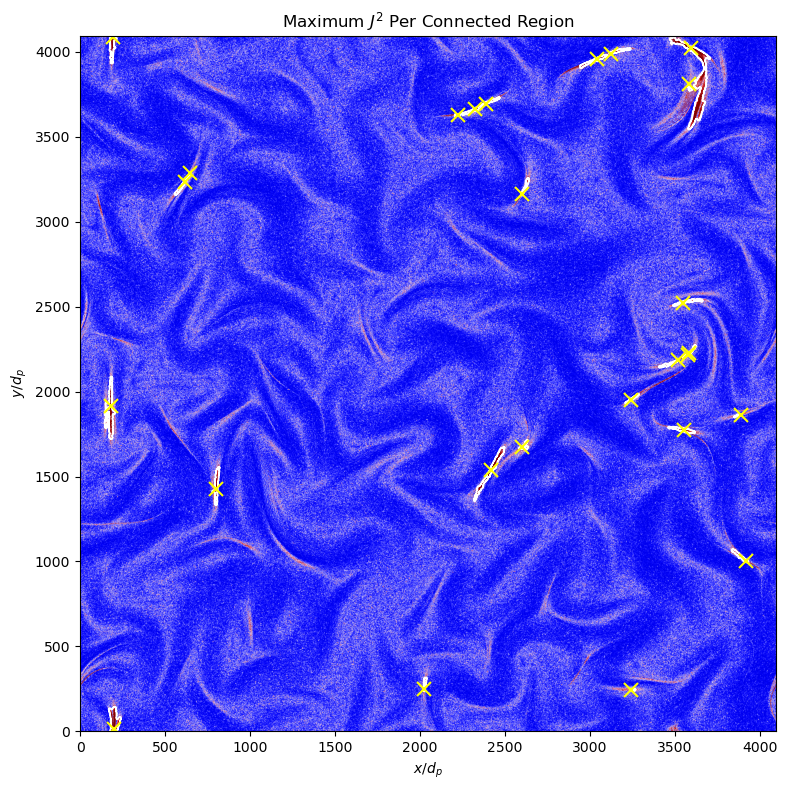

In [14]:
# PLOT ORIGINAL FIELD + MASK + MAXIMUM POINTS

plt.figure(figsize=(10, 8))

# --- Base field ---
plt.imshow(Jperp_squared.T, cmap='seismic', origin='lower', vmax=0.05)

# --- Boundaries of CSs---
boundaries = find_boundaries(labeled_mask)
plt.contour(boundaries.T, levels=[0.5], colors='white', linewidths=1)

# --- Overlay maxima as yellow crosses ---
for x, y in max_coords:
    plt.plot(x, y, marker='x', markersize=10, markeredgewidth=1.5, color='yellow')

plt.title(r'Maximum $J^{2}$ Per Connected Region')
plt.xlabel(r'$x/d_p$')
plt.ylabel(r'$y/d_p$')

plt.tight_layout()
plt.savefig(RESULTS / "Jperp_maxima_overlay_beta1.png", dpi=300)
plt.show()

In [15]:
# Method 1 for Thickness Computation: Using the internal function for diameter of largest inscribed circle

#1. Labelling each connected region

labeled_mask = measure.label(cleaned_mask, connectivity=2)
num_regions = labeled_mask.max()
print("Number of connected regions:", num_regions)

#2. Compute thicknesses

thicknesses_m1 = []

for label_id in range(1, num_regions + 1):

    region = (labeled_mask == label_id)

    # Euclidean distance transform INSIDE the region
    dist = ndi.distance_transform_edt(region)

    # Full sheet thickness = diameter of largest inscribed circle
    thickness = 2 * dist.max()

    thicknesses_m1.append(thickness)

# 3. Some Central Measures of the statistics

print(f"Found {len(thicknesses_m1)} sheets")
print(f"Mean thickness = {np.mean(thicknesses_m1):.3f} pixels")
print(f"Median thickness = {np.median(thicknesses_m1):.3f} pixels")
print(f"Min thickness = {np.min(thicknesses_m1):.3f} px, Max = {np.max(thicknesses_m1):.3f} px")

Number of connected regions: 25
Found 25 sheets
Mean thickness = 20.243 pixels
Median thickness = 16.125 pixels
Min thickness = 11.662 px, Max = 56.569 px


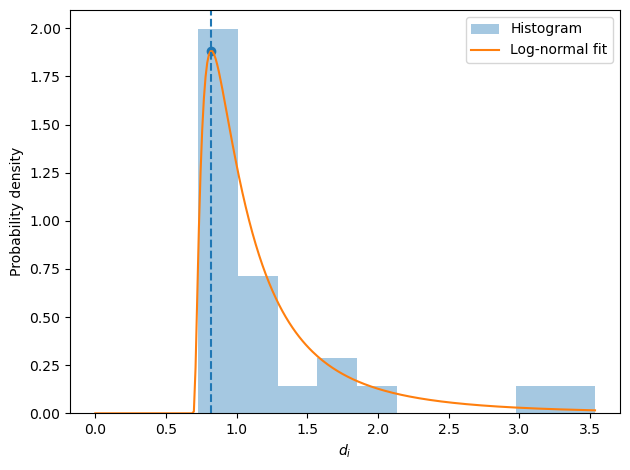

In [16]:
x = np.array(thicknesses_m1)   # in pixels
x = x[x > 0]

# Convert pixels -> d_i
x_di = x / 16.0

# Fit log-normal in d_i units
# shape, loc, scale = lognorm.fit(x_di, floc=0)
shape, loc, scale = lognorm.fit(x_di)

xs = np.linspace(0, x_di.max(), 300)

# Compute mode (peak of the PDF)
x_mode = loc + scale * np.exp(-shape**2)
y_mode = lognorm.pdf(x_mode, shape, loc, scale)

plt.hist(x_di, bins=10, density=True, alpha=0.4, label="Histogram")
plt.plot(xs, lognorm.pdf(xs, shape, loc, scale), label="Log-normal fit")

# Mark the peak
plt.axvline(x_mode, linestyle="--")
plt.scatter([x_mode], [y_mode])

plt.xlabel(r"$d_i$")
plt.ylabel("Probability density")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / "Jperp_PDF_beta1.png", dpi=300)
plt.show()